<a href="https://colab.research.google.com/github/OisinStapleton/ml-campus_data-project-colab/blob/main/MiniProjectOS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Campus Dataset Project
Oisin Stapleton

## Notes

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [24]:
import pandas as pd
from IPython.display import display, Markdown # Makes text bold
from IPython.display import display, HTML

In [28]:
display(df.head(20)) #shows first five rows

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN,NaN,NaN,NaN,NaN
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN,NaN,NaN,NaN,NaN
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN,NaN,NaN,NaN,NaN
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN,NaN,NaN,NaN,NaN
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN,NaN,NaN,NaN,NaN
5,R26_002,9/22/2026,L01 MainEntrance,Sunny,17,Moderate,Low,Traffic,Human voices,Other birds,Insects,2.0,4.0,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush,NaN,NaN,NaN,NaN
6,R26_002,9/22/2026,L04 PathFrontiHub,Windy,17,Moderate,Low,Traffic,Other,Wind,Insects,2.0,2.0,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,NaN,NaN,NaN,NaN,NaN
7,R26_002,9/22/2026,L05 GreenFrontSportsCentre,Sunny,19,Moderate,Low,Traffic,Service machinery,Wind,Other,7.0,0.0,Many,Many,Many,Many,Positive wellbeing,Vey easy,Mostly calm,Much more connected,wild plants,NaN,NaN,NaN,NaN,NaN
8,R26_002,9/22/2026,L06 HedgingBehindSportsCentre,Cloudy,16,Quiet,Low,Traffic,Human voices,Wind,Trees,3.0,1.0,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,NaN,NaN,NaN,NaN,NaN
9,R26_002,9/22/2026,L07 CarParkNearSportsCentre,Sunny,18,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6.0,2.0,Many,Many,Many,Some,Very positive wellbeing,Vey easy,Very calm,Much more connected,insects,NaN,NaN,NaN,NaN,NaN


In [27]:
# 1. Remove rows where crucial identifier information is missing
cleaned_df = df.dropna(subset=['recorder_id', 'date', 'location']).copy()

# 2. Clean and convert 'temperature_c' to integer values
# We first convert the values to numeric, turning any invalid non-numeric strings to NaN
cleaned_df['temperature_c'] = pd.to_numeric(cleaned_df['temperature_c'], errors='coerce')

# Fill any NaN temperatures with a default value (e.g., median) or drop them
median_temp = cleaned_df['temperature_c'].median()
cleaned_df['temperature_c'] = cleaned_df['temperature_c'].fillna(median_temp).astype(int)

# 3. Print the results to verify
print(f"Original rows: {len(df)}")
print(f"Cleaned rows: {len(cleaned_df)}")
display(cleaned_df[['recorder_id', 'date', 'location', 'temperature_c']].head())

Original rows: 994
Cleaned rows: 135


,recorder_id,date,location,temperature_c
0,R26_001,9/22/2026,L01 MainEntrance,16
1,R26_001,9/22/2026,L02 LibraryGreen,16
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,16
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,16
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,16


#Mean, Mode, Median

In [25]:
import pandas as pd


# 1. Identify numerical and categorical columns from our filtered dataset
# Excluding 'Not answered' placeholders when computing actual statistics
numeric_cols = ['insects_count', 'birds_count']

# Re-extract clean numeric series ignoring the 'Not answered' strings for accurate calculations
stats_df = clean_df_filtered.copy()
for col in numeric_cols:
    stats_df[col] = pd.to_numeric(stats_df[col], errors='coerce')

# 2. Calculate Mean, Median, and Mode
summary_stats = []

for col in clean_df_filtered.columns:
    # Mode can be calculated for all columns
    mode_series = clean_df_filtered[col].loc[clean_df_filtered[col] != 'Not answered'].mode()
    col_mode = mode_series.iloc[0] if not mode_series.empty else 'N/A'

    if col in numeric_cols:
        col_mean = stats_df[col].mean()
        col_median = stats_df[col].median()

        # Convert float outputs to integers as requested
        display_mean = int(round(col_mean)) if pd.notnull(col_mean) else 'N/A'
        display_median = int(col_median) if pd.notnull(col_median) else 'N/A'
        display_mode = int(col_mode) if isinstance(col_mode, (int, float)) else col_mode
    else:
        display_mean = 'N/A (Categorical)'
        display_median = 'N/A (Categorical)'
        display_mode = col_mode

    summary_stats.append({
        'Column': col,
        'Mean (Integer)': display_mean,
        'Median (Integer)': display_median,
        'Mode': display_mode
    })

# 3. Create DataFrame and display with clean styling
stats_summary_df = pd.DataFrame(summary_stats)

display(HTML("<h2 style='color:#1a73e8; font-family:Sans-Serif;'> Dataset Statistics: Mean, Median, & Mode</h2>"))
display(stats_summary_df.style.set_properties(**{
    'background-color': '#f8f9fa',
    'border-color': '#dee2e6',
    'color': '#202124'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#e8f0fe'), ('color', '#1a73e8'), ('font-weight', 'bold')]}
]))

,Column,Mean (Integer),Median (Integer),Mode
0,recorder_id,N/A (Categorical),N/A (Categorical),R26_021
1,date,N/A (Categorical),N/A (Categorical),9/22/2026
2,location,N/A (Categorical),N/A (Categorical),L06 HedgingBehindSportsCentre
3,weather,N/A (Categorical),N/A (Categorical),Sunny
4,temperature_c,N/A (Categorical),N/A (Categorical),17
5,sound level,N/A (Categorical),N/A (Categorical),Moderate
6,foot_traffic,N/A (Categorical),N/A (Categorical),Low
7,primary_sound_type_urban,N/A (Categorical),N/A (Categorical),Traffic
8,other_sound_type_urban,N/A (Categorical),N/A (Categorical),Human voices
9,primary_sound_type_nature,N/A (Categorical),N/A (Categorical),Wind


## Formatting Display

In [29]:
import numpy as np
import pandas as pd

# Ensure temperature_c is numeric for gradient rendering
preview_df = df.head(10).copy()
preview_df['temperature_c'] = pd.to_numeric(preview_df['temperature_c'], errors='coerce')
preview_df['birds_count'] = pd.to_numeric(preview_df['birds_count'], errors='coerce')

# Select a subset of columns to display neatly
styled_subset = preview_df[['date', 'location', 'weather', 'temperature_c', 'birds_count']].copy()

# Custom styling function similar to your weather example
def style_campus_data(styler):
    styler.set_caption("Campus Walk Observations (Styled Preview)")

    # Apply a background gradient to the numerical columns
    styler.background_gradient(subset=['temperature_c', 'birds_count'], cmap="YlGnBu")

    # General table formatting
    styler.set_properties(**{
        'background-color': '#f8f9fa',
        'border-color': '#dee2e6',
        'color': '#202124'
    })

    styler.set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#e8f0fe'), ('color', '#1a73e8'), ('font-weight', 'bold')]}
    ])

    return styler

# Display the styled DataFrame
display(styled_subset.style.pipe(style_campus_data))

,date,location,weather,temperature_c,birds_count
0,9/22/2026,L01 MainEntrance,Partly cloudy,16,1.000000
1,9/22/2026,L02 LibraryGreen,Sunny,16,2.000000
2,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,20.000000
3,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,2.000000
4,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,0.000000
5,9/22/2026,L01 MainEntrance,Sunny,17,4.000000
6,9/22/2026,L04 PathFrontiHub,Windy,17,2.000000
7,9/22/2026,L05 GreenFrontSportsCentre,Sunny,19,0.000000
8,9/22/2026,L06 HedgingBehindSportsCentre,Cloudy,16,1.000000
9,9/22/2026,L07 CarParkNearSportsCentre,Sunny,18,2.000000


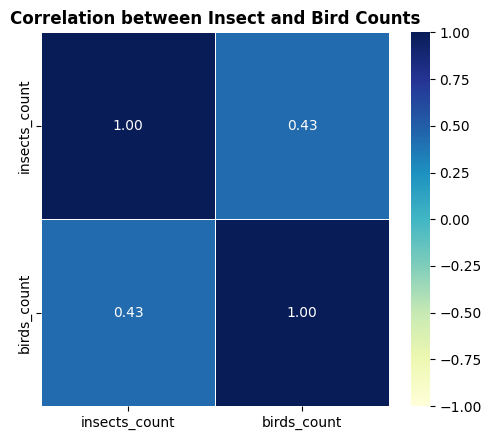

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Create a copy of the cleaned dataset and convert columns of interest to numeric
heatmap_data = cleaned_df.copy()
numeric_cols = ['insects_count', 'birds_count']
for col in numeric_cols:
    heatmap_data[col] = pd.to_numeric(heatmap_data[col], errors='coerce')

# 2. Compute the correlation matrix
correlation_matrix = heatmap_data[numeric_cols].corr()

# 3. Plot the correlation heatmap
plt.figure(figsize=(5, 4.5))
sns.heatmap(correlation_matrix, annot=True, cmap="YlGnBu", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation between Insect and Bird Counts", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

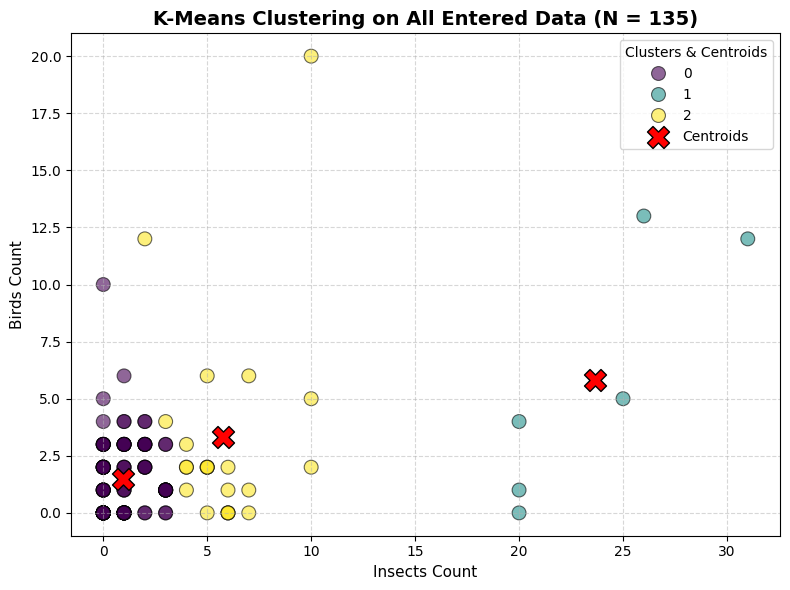

In [33]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Prepare data for clustering using all available data (df)
cluster_data = df[['insects_count', 'birds_count']].copy()
cluster_data['insects_count'] = pd.to_numeric(cluster_data['insects_count'], errors='coerce')
cluster_data['birds_count'] = pd.to_numeric(cluster_data['birds_count'], errors='coerce')

# Drop rows where counts are missing so K-Means can run, but keep all other filled rows
cluster_data = cluster_data.dropna()

# 2. Perform K-Means clustering
k_clusters = 3
k_means = KMeans(n_clusters=k_clusters, random_state=42, n_init=10)
cluster_data['cluster'] = k_means.fit_predict(cluster_data)

# 3. Plot the clusters and centroids
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='insects_count',
    y='birds_count',
    hue='cluster',
    palette='viridis',
    data=cluster_data,
    s=100,
    alpha=0.6,
    edgecolor='k'
)

# Plot centroids
centroids = k_means.cluster_centers_
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=250,
    color='red',
    marker='X',
    label='Centroids',
    edgecolor='black'
)

plt.title(f'K-Means Clustering on All Entered Data (N = {len(cluster_data)})', fontsize=14, fontweight='bold')
plt.xlabel('Insects Count', fontsize=11)
plt.ylabel('Birds Count', fontsize=11)
plt.legend(title='Clusters & Centroids')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Decision Logs

## Week6 - 15/10/26
Tinkering with potential features that could be added to project. Main reading in of the dataset was added and formatting was added for display purposes. These features are not guaranteed to be included as they were used for learning syntax and how features operate.

##Week7 - 22/10/26

Read through pandas docs to decide which features I want to implement. Data cleaned to ensure accurate representations of graphs/outputs. Inclusion of k means clustering graph and correlation graph for user readability.